<a href="https://colab.research.google.com/github/rinesl/Entity-resolution-febrl3/blob/main/entity_resolution_febrl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entity Resolution on Synthetic Person Records

**Author:** Fengting (Jessica) Jiang · **Runtime:** Google Colab (CPU) · **Data:** Febrl 3 (synthetic, public)

## The problem
Customer and identity data rarely comes with a clean, shared ID. The same person shows up several times with typos, missing fields and formatting differences. **Entity resolution** decides which records belong to the same real person and gives each person one ID.

This notebook groups 5,000 messy person records (up to 5 duplicates per person) into unique people, and **measures how accurate that grouping is** against known ground truth.

## Why
Getting identity wrong is costly in both directions:
- **False merge** (two people treated as one): wrong targeting, wrong measurement, and a privacy risk because one person's data is attached to another.
- **Missed match** (one person treated as two): inflated counts, fragmented history, weaker signals.

The core of the work is choosing and documenting that trade-off, not just running a matching library.

## Approach at a glance
| Step | What | Key metric recorded |
|---|---|---|
| 1 | Load and profile the data | records, missing rate per field |
| 2 | Clean and standardize | - |
| 3 | Blocking (limit which pairs get compared) | pair reduction, pair completeness |
| 4 | Compare fields (exact + fuzzy) | feature distributions |
| 5 | Score pairs (rule-based vs. logistic regression) | average precision |
| 6 | Choose a match cutoff | precision, recall, F1 at cutoff |
| 7 | Group matches into people (connected components) | exact-reconstruction rate, over-merges, splits |
| 8 | Error analysis | error categories |
| 9 | Summary: metrics + decision log | - |

## 0. Setup
Add three libraries for blocking, fuzzy matching etc
- `recordlinkage` - Febrl data, blocking and field comparisons
- `rapidfuzz` - fast fuzzy string similarity
- `jellyfish` - phonetic codes (Soundex) for name blocking

In [49]:
!pip install -q recordlinkage rapidfuzz jellyfish

In [50]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import jellyfish
import recordlinkage as rl #blocking
from recordlinkage.datasets import load_febrl3 #load febrl3 data
from rapidfuzz import fuzz #for fuzzy match
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                             precision_score, recall_score, f1_score) #metrics measure performance

RANDOM_STATE = 42                 # fixed seed so every number in this notebook is reproducible
os.makedirs('images', exist_ok=True)
pd.set_option('display.max_columns', 30)

# Running records of what were decided and what were measured.
metrics = {}

def log_metric(name, value):
    # Record a headline metric and echo it, so results are visible where they are produced.
    metrics[name] = value
    print(f'{name}: {value}')

## 1. Load and profile the data
**What:** Load Febrl 3 and the list of true duplicate pairs (ground truth).

**Why Febrl 3:** 5,000 records with 2,000 original people and 3,000 duplicates, up to 5 per person. Multiple duplicates per person make the clustering step realistic.

**Important:** record IDs look like `rec-1496-org` and `rec-1496-dup-0`. The middle number is the true person. I keep it for evaluation.

In [51]:
df, true_links = load_febrl3(return_links=True)

# Ground truth: the true person behind each record (evaluation only - never a feature).
df['true_person_id'] = df.index.str.split('-').str[1]

# True duplicate pairs as unordered sets, so (a, b) and (b, a) count as the same pair.
true_pairs = set(map(frozenset, true_links))

log_metric('records', len(df))
log_metric('true people', df['true_person_id'].nunique())
log_metric('true duplicate pairs', len(true_pairs))
df.head()

records: 5000
true people: 2000
true duplicate pairs: 6538


,given_name,surname,street_number,address_1,address_2,suburb,postcode,state,date_of_birth,soc_sec_id,true_person_id
rec_id,,,,,,,,,,,
rec-1496-org,mitchell,green,7,wallaby place,delmar,cleveland,2119,sa,19560409,1804974,1496
rec-552-dup-3,harley,mccarthy,177,pridhamstreet,milton,marsden,3165,nsw,19080419,6089216,552
rec-988-dup-1,madeline,mason,54,hoseason street,lakefront retrmnt vlge,granville,4881,nsw,19081128,2185997,988
rec-1716-dup-1,isabelle,NaN,23,gundulu place,currin ga,utakarra,2193,wa,19921119,4314184,1716
rec-1213-org,taylor,hathaway,7,yuranigh court,brentwood vlge,NaN,4220,nsw,19991207,9144092,1213


In [52]:
# Profile: missing values and distinct values per field.
# This tells us which fields are reliable enough to block or match on.
fields = ['given_name', 'surname', 'street_number', 'address_1', 'address_2',
          'suburb', 'postcode', 'state', 'date_of_birth', 'soc_sec_id']
profile = pd.DataFrame({
    'missing %': (df[fields].isna().mean() * 100).round(1),
    'distinct values': df[fields].nunique(),
})
profile

,missing %,distinct values
given_name,3.1,1213
surname,1.6,1740
street_number,4.9,342
address_1,3.1,2358
address_2,13.9,2303
suburb,1.7,1706
postcode,0.0,1273
state,1.7,35
date_of_birth,3.1,2089
soc_sec_id,0.0,2291


In [53]:
# --- Data-quality check on soc_sec_id (profiling) ---
ssn = df['soc_sec_id'].astype('string').str.strip()
present = ssn.dropna()

expected_len = present.str.len().mode()[0]

ssn_quality = pd.Series({
    'records': len(ssn),
    'missing %': ssn.isna().mean() * 100,
    'digits only % (of present)': present.str.fullmatch(r'\d+').mean() * 100,
    f'length = {expected_len} % (of present)': (present.str.len() == expected_len).mean() * 100,
    'distinct values': present.nunique(),
    'records whose SSN appears more than once %': present.duplicated(keep=False).mean() * 100,
}).round(2)
print(ssn_quality.to_string())

print('\nLength distribution (length -> record count):')
print(present.str.len().value_counts().sort_index().to_string())

# Using ground truth: is the SSN consistent within one person, and unique across people?
checks = df.assign(ssn=ssn)
by_person = checks.groupby('true_person_id')['ssn'].nunique()
by_ssn = checks.groupby('ssn')['true_person_id'].nunique()
print(f"\nPeople whose records all carry the same SSN: {(by_person == 1).mean():.1%}")
print(f"People with 2+ different SSNs (typos/variants): {(by_person > 1).sum()}")
print(f"SSN values shared by 2+ different people (collisions): {(by_ssn > 1).sum()}")

records                                       5000.00
missing %                                        0.00
digits only % (of present)                     100.00
length = 7 % (of present)                      100.00
distinct values                               2291.00
records whose SSN appears more than once %      76.72

Length distribution (length -> record count):
soc_sec_id
7    5000

People whose records all carry the same SSN: 87.3%
People with 2+ different SSNs (typos/variants): 254
SSN values shared by 2+ different people (collisions): 0


**Reading the profile:** fields with few missing values and many distinct values (names, date of birth, postcode) are the most useful for matching. Fields with many missing values (e.g., `address_2`) are weak evidence and get low weight later.

**Decision - leave out `soc_sec_id`:** real identity data (devices, cookies, partner records) rarely has a clean unique ID. Matching on one would make the problem trivial and the results misleading, so I treat it as unavailable. soc_sec_id is a synthetic, unencoded ID: no real PII. In production, this field would arrive hashed or tokenized, which limits it to exact matching.

## 2. Clean and standardize
**What:** lower-case, trim spaces, turn empty strings into missing values, and add a Soundex code for surnames.

**Why:** formatting differences ("Smith " vs. "smith") should never count as disagreements. Missing values must stay missing (not empty strings) so the comparison step scores them as "no evidence" rather than as a match or mismatch.

**Soundex:** a phonetic code (e.g., "Smith" and "Smyth" both become `S530`). Used only for blocking in Step 3, so spelling variants still end up in the same block.

In [54]:
def clean(series):
    # Standardize a text column: lower case, trimmed; blanks become missing (NaN).
    s = series.astype(str).str.lower().str.strip()
    s = s.where(series.notna() & (s != '') & (s != 'nan'), np.nan)
    return s

for col in fields:
    df[col] = clean(df[col])

df['surname_sdx'] = df['surname'].apply(lambda x: jellyfish.soundex(x) if pd.notna(x) else np.nan)

# Blocking keys: a missing value gets a unique placeholder so records with missing fields
# are never blocked together just because they are both blank.
for col in ['postcode', 'surname_sdx', 'given_name']:
    df[f'{col}_key'] = df[col].fillna(pd.Series('missing_' + df.index, index=df.index))

# Full address string, used for an order-insensitive fuzzy comparison in Step 4.
df['full_address'] = (df[['street_number', 'address_1', 'address_2', 'suburb']]
                      .fillna('').agg(' '.join, axis=1).str.split().str.join(' '))
df[['given_name', 'surname', 'surname_sdx', 'full_address', 'date_of_birth', 'postcode']].head()

,given_name,surname,surname_sdx,full_address,date_of_birth,postcode
rec_id,,,,,,
rec-1496-org,mitchell,green,G650,7 wallaby place delmar cleveland,19560409,2119
rec-552-dup-3,harley,mccarthy,M263,177 pridhamstreet milton marsden,19080419,3165
rec-988-dup-1,madeline,mason,M250,54 hoseason street lakefront retrmnt vlge granville,19081128,4881
rec-1716-dup-1,isabelle,NaN,NaN,23 gundulu place currin ga utakarra,19921119,2193
rec-1213-org,taylor,hathaway,H300,7 yuranigh court brentwood vlge,19991207,4220


## 3. Blocking
**What:** only compare pairs of records that share a "blocking key".

**Why:** 5,000 records give about 12.5 million possible pairs. Real identity data has millions or billions of records, so comparing every pair is impossible. Blocking keeps the comparison count manageable.

**The trade-off:** every blocking rule can drop a true match (e.g., a typo in the postcode). Two numbers capture this:
- **Reduction ratio** - share of all possible pairs kill before comparing (higher = cheaper)
- **Pair completeness** - share of true matches that survive blocking (higher = fewer matches lost before scoring even starts)

**Options considered:** a single key vs. several keys combined (a pair is kept if it matches on *any* key). I first measure each pass alone and combined, then decide.

In [55]:
n = len(df)
all_pairs = n * (n - 1) // 2

def evaluate_blocking(indexer, name):
    # Run a blocking candidates and report how many pairs it keeps and how many true matches survive.
    candidates = indexer.index(df)
    kept_true = sum(frozenset(p) in true_pairs for p in candidates)
    return {'strategy': name,
            'candidate pairs': len(candidates),
            'reduction ratio': round(1 - len(candidates) / all_pairs, 5),
            'pair completeness': round(kept_true / len(true_pairs), 4)}

def make_index(*passes):
    # Build an index that combines blocking passes; a pair is kept if any pass keeps it.
    idx = rl.Index()
    for kind, col in passes:
        if kind == 'block':
            idx.block(col)
        else:
            idx.sortedneighbourhood(col, window=5)   # compares records with similar sorted names
    return idx

strategies = {
    'postcode only': [('block', 'postcode_key')],
    'surname Soundex only': [('block', 'surname_sdx_key')],
    'sorted given name only': [('sn', 'given_name_key')],
    'all three combined': [('block', 'postcode_key'), ('block', 'surname_sdx_key'), ('sn', 'given_name_key')],
}
blocking_results = pd.DataFrame([evaluate_blocking(make_index(*p), name) for name, p in strategies.items()])
blocking_results

,strategy,candidate pairs,reduction ratio,pair completeness
0,postcode only,16115,0.99871,0.7631
1,surname Soundex only,53559,0.99571,0.6779
2,sorted given name only,71235,0.99430,0.6764
3,all three combined,132861,0.98937,0.9540


###**Note**:
Each single blocking key kept only 68 to 76% of true matches, because every field has typos. The three keys mostly catch different pairs, so combining them raised pair completeness to 95.4% while still skipping 98.9% of comparisons. That sets a recall ceiling of about 95% for the whole pipeline. Completeness came in a bit below what independent errors would predict, which suggests some records are corrupted in several fields at once. A date-of-birth pass would be my next lever if recall mattered more.



In [56]:
# Blocking decision: the combined candidate (see markdown below for rationale).
candidates = make_index(*strategies['all three combined']).index(df)
best = blocking_results.set_index('strategy').loc['all three combined']

log_metric('blocking: candidate pairs', int(best['candidate pairs']))
log_metric('blocking: reduction ratio', float(best['reduction ratio']))
log_metric('blocking: pair completeness', float(best['pair completeness']))

blocking: candidate pairs: 132861
blocking: reduction ratio: 0.98937
blocking: pair completeness: 0.954


**Reading the table:** each single key loses some true matches (a typo in that field breaks the block). Combining three independent keys recovers most of them while still avoiding the vast majority of comparisons. Any true match lost here can never be recovered later, so **overall recall = pair completeness x scoring recall**.

## 4. Compare fields
**What:** for each candidate pair, compute a 0-1 similarity per field.

**Options considered and decisions:**
| Field | Method | Why |
|---|---|---|
| given name, surname, suburb | Jaro-Winkler | Built for short strings like names; rewards matching beginnings, tolerant of small typos |
| address_1 | Levenshtein | Counts character edits; suits longer strings |
| full address | rapidfuzz token-sort ratio | Ignores word order ("12 main st" vs. "main st 12") |
| date of birth, postcode, street number | exact | Typos here usually mean a real difference, and partial credit adds noise |

Missing values score 0 (no evidence) rather than counting as a match.

I keep continuous scores (no thresholds per field) so I can draw a precision/recall curve in Step 6.

In [57]:
c = rl.Compare()
c.string('given_name', 'given_name', method='jarowinkler', label='given_name')
c.string('surname', 'surname', method='jarowinkler', label='surname')
c.string('suburb', 'suburb', method='jarowinkler', label='suburb')
c.string('address_1', 'address_1', method='levenshtein', label='address_1')
c.exact('date_of_birth', 'date_of_birth', label='date_of_birth')
c.exact('postcode', 'postcode', label='postcode')
c.exact('street_number', 'street_number', label='street_number')
features = c.compute(candidates, df)

# Order-insensitive fuzzy score on the full address (0-1). Empty addresses give no evidence.
addr = df['full_address']
def token_sort(a, b):
    return fuzz.token_sort_ratio(a, b) / 100 if a and b else 0.0
features['full_address'] = [token_sort(addr[i], addr[j]) for i, j in features.index]

# Label each candidate pair with ground truth (for evaluation and the supervised model).
y = pd.Series([frozenset(p) in true_pairs for p in features.index], index=features.index, name='is_match')

log_metric('candidate pairs that are true matches (%)', round(y.mean() * 100, 2))
features.describe().T[['mean', 'min', 'max']]

candidate pairs that are true matches (%): 4.69


,mean,min,max
given_name,0.665462,0.0,1.0
surname,0.610283,0.0,1.0
suburb,0.465503,0.0,1.0
address_1,0.287110,0.0,1.0
date_of_birth,0.040606,0.0,1.0
postcode,0.121292,0.0,1.0
street_number,0.046161,0.0,1.0
full_address,0.397388,0.0,1.0


In [58]:
# Sanity check: true matches should score clearly higher than non-matches on every field.
features.groupby(y).mean().T.rename(columns={False: 'non-match mean', True: 'match mean'}).round(3)

is_match,non-match mean,match mean
given_name,0.658,0.823
surname,0.598,0.867
suburb,0.443,0.915
address_1,0.260,0.840
date_of_birth,0.000,0.865
postcode,0.088,0.800
street_number,0.012,0.742
full_address,0.375,0.853


## 5. Score each pair
**What:** combine field similarities into one match score per pair.

**Options considered:**
1. **Rule-based weighted score** - transparent, needs no labels, easy to explain to stakeholders. Weights reflect how identifying each field is.
2. **Logistic regression** - learns weights from labeled pairs. Usually more accurate, but needs labels, which real projects often have only through a manual-review sample.

**Evaluation design:** 70/30 train/test split, stratified so both sets have the same match rate. Both scorers are evaluated on the same test pairs.

In [59]:
# Rule-based weights (sum to 1). Names and DOB are the most identifying; address detail and suburb add support.
weights = {'given_name': 0.20, 'surname': 0.20, 'date_of_birth': 0.20, 'full_address': 0.15,
           'address_1': 0.05, 'postcode': 0.10, 'street_number': 0.05, 'suburb': 0.05}
assert abs(sum(weights.values()) - 1) < 1e-9
rule_score = sum(features[col] * w for col, w in weights.items())

X_train, X_test, y_train, y_test = train_test_split(
    features, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

model = LogisticRegression(max_iter=1000, class_weight='balanced')   # balanced: matches are the minority class
model.fit(X_train, y_train)

test_scores = {
    'rule-based': rule_score.loc[X_test.index].values,
    'logistic regression': model.predict_proba(X_test)[:, 1],
}
for name, s in test_scores.items():
    log_metric(f'average precision - {name}', round(average_precision_score(y_test, s), 4))

# Learned weights, for comparison with the hand-set ones.
pd.Series(model.coef_[0], index=features.columns).sort_values(ascending=False).round(2)

average precision - rule-based: 0.9961
average precision - logistic regression: 0.9997


,0
full_address,11.59
date_of_birth,10.32
surname,6.40
suburb,5.91
postcode,4.87
given_name,4.74
address_1,3.73
street_number,3.43


## 6. Measure match quality and choose a cutoff
**What:** plot precision vs. recall for both scorers, then pick the score cutoff above which a pair counts as a match.

- **Precision** - of the pairs matches, how many are real
- **Recall** - of the real matches, how many can be found

**Decision rule:** choose the cutoff that gives the **highest recall while keeping precision at or above 98%**.

**Rationale:** a false merge attaches one person's data to another - worse for targeting accuracy and privacy than missing a match, which only leaves a person split in two. protect precision first

> Note: The 98% target is a **business choice** and would be set with stakeholders in a real project.

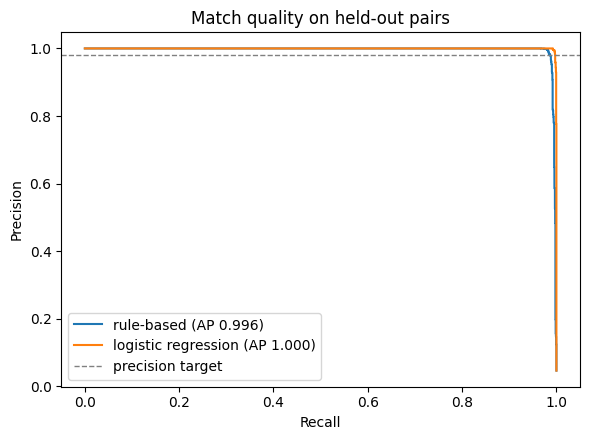

In [60]:
PRECISION_TARGET = 0.98 #business decision

plt.figure(figsize=(6, 4.5))
for name, s in test_scores.items():
    p, r, _ = precision_recall_curve(y_test, s)
    plt.plot(r, p, label=f'{name} (AP {average_precision_score(y_test, s):.3f})')
plt.axhline(PRECISION_TARGET, color='grey', linestyle='--', linewidth=1, label='precision target')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Match quality on held-out pairs')
plt.legend(); plt.tight_layout(); plt.savefig('images/precision_recall.png', dpi=150); plt.show()

In [61]:
def pick_cutoff(y_true, scores, precision_target):
    # Return the cutoff with the highest recall among cutoffs that meet the precision target.
    p, r, t = precision_recall_curve(y_true, scores)
    ok = np.where(p[:-1] >= precision_target)[0]          # p and r have one more element than t
    if len(ok) == 0:                                      # target unreachable: fall back to best F1
        f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
        return t[np.argmax(f1)]
    best = ok[np.argmax(r[ok])]
    return t[best]

chosen_model = 'logistic regression' #picked logistic regression for higher performance
CUTOFF = pick_cutoff(y_test, test_scores[chosen_model], PRECISION_TARGET)
pred = test_scores[chosen_model] >= CUTOFF

log_metric('chosen scorer', chosen_model)
log_metric('match cutoff', round(float(CUTOFF), 3))
log_metric('pair precision (test)', round(precision_score(y_test, pred), 4))
log_metric('pair recall (test)', round(recall_score(y_test, pred), 4))
log_metric('pair F1 (test)', round(f1_score(y_test, pred), 4))
log_metric('end-to-end recall (completeness x recall)',
           round(metrics['blocking: pair completeness'] * metrics['pair recall (test)'], 4))

# Cutoff sensitivity: what moving the cutoff would cost or gain - the table a stakeholder would ask for.
rows = []
for cut in [0.3, 0.5, 0.7, round(float(CUTOFF), 3), 0.9, 0.95]:
    pr = test_scores[chosen_model] >= cut
    rows.append({'cutoff': cut, 'precision': round(precision_score(y_test, pr, zero_division=0), 4),
                 'recall': round(recall_score(y_test, pr), 4), 'pairs called matches': int(pr.sum())})
pd.DataFrame(rows).sort_values('cutoff')

chosen scorer: logistic regression
match cutoff: 0.412
pair precision (test): 0.98
pair recall (test): 0.9973
pair F1 (test): 0.9886
end-to-end recall (completeness x recall): 0.9514


,cutoff,precision,recall,pairs called matches
0,0.300,0.9694,0.9973,1925
3,0.412,0.9800,0.9973,1904
1,0.500,0.9868,0.9968,1890
2,0.700,0.9936,0.9963,1876
4,0.900,0.9979,0.9925,1861
5,0.950,1.0000,0.9904,1853


## 7. Group matched records into people
**What:** treat records as nodes and matched pairs as edges, then take **connected components** - every group of records linked directly or indirectly becomes one person with one `resolved_id`.

**Why:** matching is pairwise, but the business needs one ID per person. Components turn pairs into consistent groups (if A=B and B=C, then A, B and C share an ID).

**Risk:** one bad edge can merge two different people's groups (A=B, B=C, but A and C are different).check cluster sizes and inspect the largest clusters

**Evaluation is at the person level, not just the pair level:**
- **Exact reconstruction rate** - share of true people whose records form exactly one cluster with no one else's
- **Over-merged clusters** - clusters containing more than one true person (false merges)
- **Split people** - true people spread across more than one cluster (missed matches)

> Note: score all candidate pairs, including the ones the model trained on

In [62]:
all_scores = pd.Series(model.predict_proba(features)[:, 1], index=features.index)
matched_pairs = all_scores.index[all_scores >= CUTOFF]

G = nx.Graph()
G.add_nodes_from(df.index)          # every record is a node, so unmatched records become clusters of one
G.add_edges_from(matched_pairs)
cluster_of = {rec: i for i, comp in enumerate(nx.connected_components(G)) for rec in comp}
df['resolved_id'] = df.index.map(cluster_of)

def person_level_eval(frame):
    # Compare resolved clusters with true people and return the person-level metrics.
    true_groups = frame.groupby('true_person_id').groups
    res_groups = frame.groupby('resolved_id').groups
    exact = sum(set(recs) == set(res_groups[frame.loc[recs[0], 'resolved_id']])
                for recs in true_groups.values())
    over_merged = (frame.groupby('resolved_id')['true_person_id'].nunique() > 1).sum()
    split = (frame.groupby('true_person_id')['resolved_id'].nunique() > 1).sum()
    return {'exact reconstruction rate': round(exact / len(true_groups), 4),
            'over-merged clusters': int(over_merged),
            'split people': int(split),
            'resolved clusters': frame['resolved_id'].nunique(),
            'true people': len(true_groups)}

for k, v in person_level_eval(df).items():
    log_metric(f'person-level: {k}', v)

person-level: exact reconstruction rate: 0.9265
person-level: over-merged clusters: 50
person-level: split people: 45
person-level: resolved clusters: 1990
person-level: true people: 2000


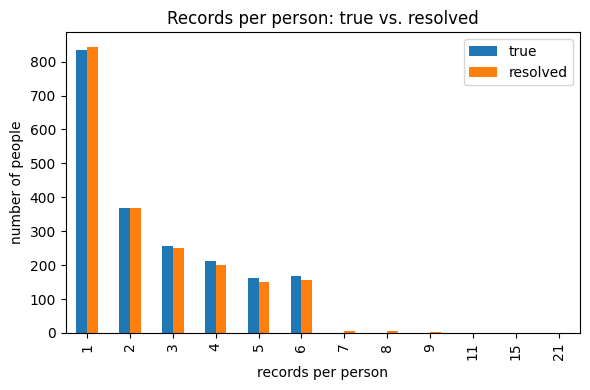

,resolved_id,true_person_id,given_name,surname,date_of_birth,full_address
rec_id,,,,,,
rec-375-dup-2,151,375,sma,webb,19361215,5 deamer cerescent belaradah west lakes shore
rec-482-dup-4,151,482,frahn,lauren,19180701,5 solomon crescent stoney creek leichhardt
rec-482-org,151,482,lauren,frahn,19180701,5 solomon crescent stoney creek leichhardt
rec-375-dup-1,151,375,webb,sam,19880611,5 deamer crescent belaradah west lakes shore
rec-375-dup-0,151,375,sam,webb,19361215,5 deamer cerscent belaradah west lakes shore
rec-375-org,151,375,sam,webb,19361215,5 deamer crescent belaradah west lakes shore
rec-375-dup-3,151,375,sam,web,19361215,5 deamer crescent belaradah daw park
rec-482-dup-1,151,482,lauren,frahn,19180701,5 solomon crescent stoney rceek leichhardt
rec-482-dup-3,151,482,lauren,frahn,19180701,5 solomon crescent stoney rceek leichhardt


In [63]:
# Cluster-size distribution: resolved vs. true. A long tail of large resolved clusters would signal chaining.
sizes = pd.DataFrame({
    'true': df['true_person_id'].value_counts().value_counts().sort_index(),
    'resolved': df['resolved_id'].value_counts().value_counts().sort_index(),
}).fillna(0).astype(int)
sizes.plot(kind='bar', figsize=(6, 4), title='Records per person: true vs. resolved')
plt.xlabel('records per person'); plt.ylabel('number of people'); plt.tight_layout()
plt.savefig('images/cluster_sizes.png', dpi=150); plt.show()

# Inspect the largest resolved clusters - the first place chaining would show up.
largest = df['resolved_id'].value_counts().head(3).index
df[df['resolved_id'].isin(largest)].sort_values('resolved_id')[
    ['resolved_id', 'true_person_id', 'given_name', 'surname', 'date_of_birth', 'full_address']]

## 8. Error analysis
**What:** look at real examples of the two error types and group them by cause.

**Why:** headline metrics say *how much* error there is; examples say *why*, which decides the next fix (better cleaning, another blocking key, a new feature, or a different cutoff).

In [64]:
def show_pairs(pairs, n=5):
    # Show the two records of each pair side by side, with the model score.
    cols = ['given_name', 'surname', 'date_of_birth', 'full_address', 'postcode']
    out = []
    for a, b in list(pairs)[:n]:
        out.append(pd.concat([df.loc[[a], cols], df.loc[[b], cols]]).assign(score=round(all_scores.get((a, b), np.nan), 3)))
    return pd.concat(out) if out else pd.DataFrame()

y_all = y.reindex(all_scores.index)
false_merges = all_scores[(all_scores >= CUTOFF) & (~y_all)].sort_values(ascending=False).index
missed_scored = all_scores[(all_scores < CUTOFF) & (y_all)].sort_values(ascending=False).index
cand_set = set(map(frozenset, candidates))
missed_by_blocking = [tuple(p) for p in true_pairs if p not in cand_set]

log_metric('false merges (pairs)', len(false_merges))
log_metric('missed matches - scored below cutoff', len(missed_scored))
log_metric('missed matches - removed by blocking', len(missed_by_blocking))

print('\nFalse merges (highest scores first):')
display(show_pairs(false_merges))
print('\nMissed matches that were scored but fell below the cutoff:')
display(show_pairs(missed_scored))

false merges (pairs): 111
missed matches - scored below cutoff: 15
missed matches - removed by blocking: 301

False merges (highest scores first):


,given_name,surname,date_of_birth,full_address,postcode,score
rec_id,,,,,,
rec-707-dup-2,amelia,strck,19640131,29 winser crescent pangani coffs harbour,2250,0.931
rec-1179-dup-2,tohmas,priets,19401205,29 nemarang crescent new farm,2250,0.931
rec-1179-dup-2,tohmas,priets,19401205,29 nemarang crescent new farm,2250,0.926
rec-707-org,amelia,struck,19640311,29 winser crescent pangani coffs harbour,2250,0.926
rec-1375-org,joshua,robson,19770906,12 windich street indra lansvale,6153,0.920
rec-1421-org,thomas,milburn,19080629,12 sheehy street witsend kilcoy,6153,0.920
rec-497-dup-2,alexandra,clarke,19190129,184 sadlier street yakatoon franksgon,2756,0.919
rec-1362-dup-0,lil,clarke,19460126,14 torrens street wal 53581 orange,2756,0.919
rec-1598-org,tai,toews,19810610,16 badimara street kodootonga maitland,4818,0.913



Missed matches that were scored but fell below the cutoff:


,given_name,surname,date_of_birth,full_address,postcode,score
rec_id,,,,,,
rec-1062-dup-3,kylie,dixon,19000404,4 sanford xplace white lofdge phillip,5047,0.352
rec-1062-dup-1,madison,dixson,19940413,37 white lodge ringwoid,5047,0.352
rec-1128-dup-0,jack,stubbs,19830223,150 curnow jlace summe erset st agnes,5344,0.270
rec-1128-dup-4,stubbs,jaxck,19890526,150 heard sreet summerset st agnes,5344,0.270
rec-985-dup-4,felicity,NaN,NaN,25 federal highway argy le mayfield,4125,0.259
rec-985-dup-3,felicity,pulford,19860610,3 federalhighway argyle charlestown,4125,0.259
rec-255-dup-0,zachary,hude,NaN,3 spofforth street oakleaves eldorado,2014,0.249
rec-255-dup-1,zachary,hude,19813005,3 hallstrom circuit kogagh,2016,0.249
rec-304-dup-3,james,sebregts,19040404,64 holden crescent ngunnawal,3340,0.191


**Write-up template - fill in after looking at the examples:**

| Error type | Count | Main causes observed | Possible fix |
|---|---|---|---|
| False merges | 111 | e.g., shared address and similar names (household) | stricter address + DOB rule, or household-level IDs |
| Missed - below cutoff | 15 | e.g., swapped first/last name, DOB typo | add a swapped-name feature; partial-date match |
| Missed - by blocking | 301 | e.g., typos in all three blocking keys | add a date-of-birth blocking pass |

## 9. Summary
### Headline metrics

In [66]:
pd.DataFrame(list(metrics.items()), columns=['metric', 'value'])

,metric,value
0,records,5000
1,true people,2000
2,true duplicate pairs,6538
3,blocking: candidate pairs,132861
4,blocking: reduction ratio,0.98937
5,blocking: pair completeness,0.954
6,candidate pairs that are true matches (%),4.69
7,average precision - rule-based,0.9961
8,average precision - logistic regression,0.9997
9,chosen scorer,logistic regression


### Trade-off Analysis
I chose a cutoff of 0.412, which keeps precision at 98% and finds 99.7% of the true matches that were scored. I protected precision because merging two people is worse for targeting and privacy than missing a match. End to end, the system recovers 95.1% of all true matches and reconstructs 92.7% of people exactly (1,990 clusters vs. 2,000 true people; 50 over-merged clusters, 45 split people). Most remaining errors come from blocking — 301 of 316 missed pairs (95%) never reached the scorer, which I'd address next with an additional blocking pass on date of birth..

### How I'd run this in production
- **Monitor match quality** weekly: match rate, cluster-size distribution and drift, share of new records joining existing clusters.
- **Ground truth without labels:** review a random sample of matches and non-matches each cycle to estimate precision and recall.
- **Alert on anomalies:** a cluster that suddenly grows large is a chaining signal and should block downstream use until reviewed.
- **Next modeling steps:** unsupervised probabilistic matching (Fellegi-Sunter / Splink), a household layer on top of person IDs, and GraphFrames for distributed clustering.
